In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

from pipelines import get_rf_pipeline

In [2]:
spectra = pd.read_csv(
    "../data/processed_spectra.csv",
    index_col=0
)

X = spectra.drop(columns=["Label"])
y = spectra["Label"]

In [3]:
param_grid = {

    "classifier__n_estimators": [100, 300, 500],

    "classifier__max_depth": [None, 10, 20, 30],

    "classifier__min_samples_split": [2, 5, 10],

    "classifier__min_samples_leaf": [1, 2, 4],

    "classifier__max_features": ["sqrt", "log2"]
}

In [4]:
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [5]:
accuracies = []
precisions = []
recalls = []
f1_scores = []
auc_scores = []
specificities = []

all_true = []
all_pred = []
all_prob = []

for train_idx, test_idx in outer_cv.split(X, y):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        estimator=get_rf_pipeline(),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_

    y_pred = best_model.predict(X_test)

    y_prob = best_model.predict_proba(X_test)[:,1]

    accuracies.append(
        accuracy_score(y_test, y_pred)
    )

    precisions.append(
        precision_score(y_test, y_pred)
    )

    recalls.append(
        recall_score(y_test, y_pred)
    )

    f1_scores.append(
        f1_score(y_test, y_pred)
    )

    auc_scores.append(
        roc_auc_score(y_test, y_prob)
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    specificities.append(
        tn / (tn + fp)
    )

    all_true.extend(y_test)
    all_pred.extend(y_pred)
    all_prob.extend(y_prob)

In [6]:
metrics = {

    "Accuracy": accuracies,
    "Precision": precisions,
    "Recall": recalls,
    "Specificity": specificities,
    "F1": f1_scores,
    "ROC-AUC": auc_scores
}

for name, values in metrics.items():

    print(
        f"{name:15s}: "
        f"{np.mean(values):.3f} ± {np.std(values):.3f}"
    )

Accuracy       : 0.903 ± 0.072
Precision      : 0.946 ± 0.066
Recall         : 0.861 ± 0.157
Specificity    : 0.946 ± 0.066
F1             : 0.890 ± 0.093
ROC-AUC        : 0.988 ± 0.010


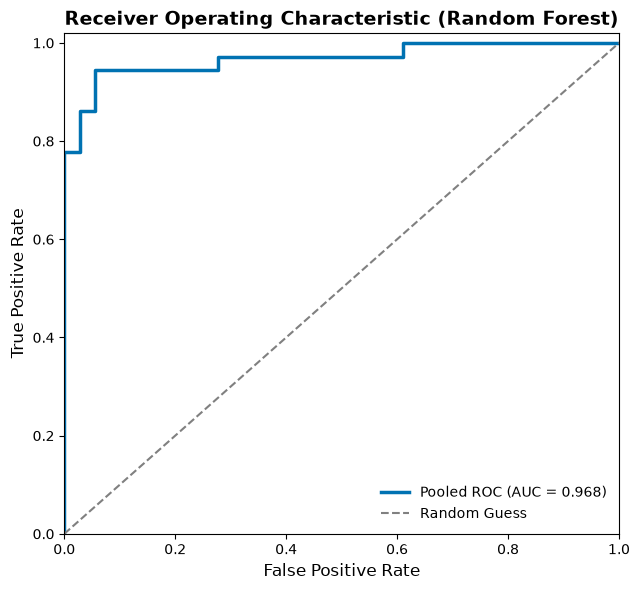

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(all_true, all_prob)
auc = roc_auc_score(all_true, all_prob)

plt.style.use("default")

plt.figure(figsize=(6.5, 6))

plt.plot(
    fpr,
    tpr,
    color="#0072B2",
    linewidth=2.5,
    label=f"Pooled ROC (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    linewidth=1.5,
    label="Random Guess"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "Receiver Operating Characteristic (Random Forest)",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    frameon=False,
    loc="lower right"
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    "../figures/Figure5_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

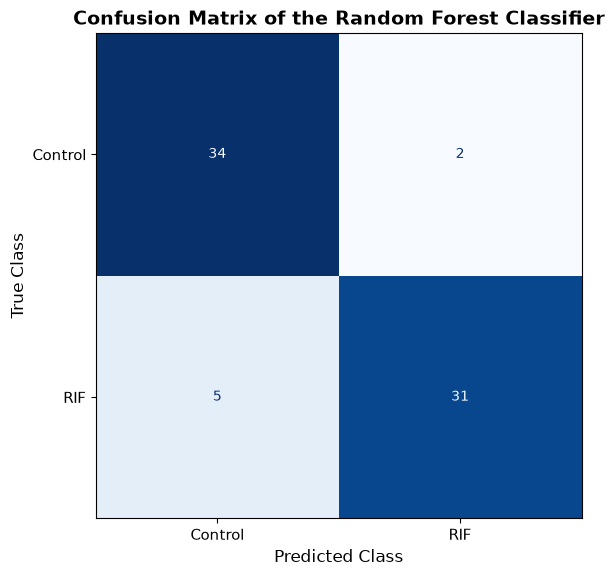

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_true, all_pred)

plt.style.use("default")

fig, ax = plt.subplots(figsize=(6, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Control", "RIF"]
)

disp.plot(
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=ax
)

plt.title(
    "Confusion Matrix of the Random Forest Classifier",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("True Class", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()

plt.savefig(
    "../figures/Figure6_ConfusionMatrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()